# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

Name:Nida Hameed Roll No: 2024_SE_41

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

### Task1(a)-Load the CSV file and print its shape

In [26]:

df = pd.read_csv("pakistan_used_cars_clean.csv")

print("T1(a): Dataset Shape:", df.shape)

T1(a): Dataset Shape: (20484, 11)


### Task1(b)-Filter the Corolla GLI data

In [27]:
gli = df[
    (df["Model"] == "Corolla GLI") &
    (df["Transaction Type"] == "Cash") &
    (df["Year"].between(2005, 2018)) &
    (df["Price_lakh"].between(5, 40))
].copy()

print("T1(b): Filtered Dataset Shape:", gli.shape)

T1(b): Filtered Dataset Shape: (796, 11)


### Task1(c)-Display summary statistics

In [28]:

print("T1(c): Summary Statistics")

display(gli[["Age", "Price_lakh"]].describe())

T1(c): Summary Statistics


,Age,Price_lakh
count,796.000000,796.000000
mean,6.445980,16.586237
std,3.107847,3.984407
min,2.000000,6.543210
25%,4.000000,13.500000
50%,6.000000,16.500000
75%,9.000000,19.500000
max,15.000000,30.000000


### Task1(d)-Calculate Correlation

In [29]:
correlation = gli["Age"].corr(gli["Price_lakh"])

print("T1(d): Correlation:", correlation)

T1(d): Correlation: -0.8956521001869919


### Task1(e)-Create a scatter plot

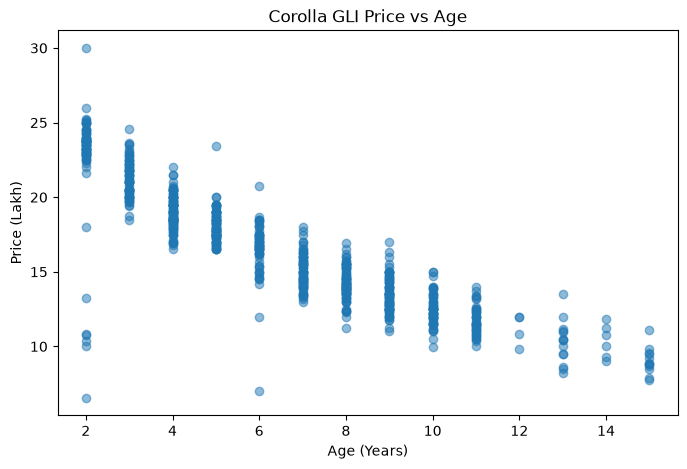

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    gli["Age"],
    gli["Price_lakh"],
    alpha=0.5
)

plt.title("Corolla GLI Price vs Age")
plt.xlabel("Age (Years)")
plt.ylabel("Price (Lakh)")

plt.show()

### Task1-Written Answer

A straight line is a sensible model for this data because the correlation between Age and Price_lakh is strongly negative. The scatter plot also shows a decreasing relationship between car age and price. This means that as the age of a Corolla GLI increases, its price generally decreases. Therefore, simple linear regression is suitable for this dataset.

## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

### Task2(a)-Create X and Y


In [31]:
X = gli[["Age"]]
y = gli["Price_lakh"]

print("T2(a): X Shape:", X.shape)
print("T2(a): y Shape:", y.shape)

T2(a): X Shape: (796, 1)
T2(a): y Shape: (796,)


### Task2(b)-Split the dataset into training and testing Data

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("T2(b): X_train Shape:", X_train.shape)
print("T2(b): X_test Shape:", X_test.shape)
print("T2(b): y_train Shape:", y_train.shape)
print("T2(b): y_test Shape:", y_test.shape)

T2(b): X_train Shape: (636, 1)
T2(b): X_test Shape: (160, 1)
T2(b): y_train Shape: (636,)
T2(b): y_test Shape: (160,)


### Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

### Task3(a)-Calculate the Means of X and Y


In [34]:
x_mean = X_train["Age"].mean()
y_mean = y_train.mean()

print("T3(a): Mean of x:", x_mean)
print("T3(a): Mean of y:", y_mean)

T3(a): Mean of x: 6.382075471698113
T3(a): Mean of y: 16.653325314465405


### Task3(b)-Calculate Slope and Intercept

In [35]:
x = X_train["Age"].to_numpy()
y_values = y_train.to_numpy()

b1 = np.sum((x - x_mean) * (y_values - y_mean)) / np.sum((x - x_mean) ** 2)

b0 = y_mean - b1 * x_mean

print("T3(b): Slope (b1):", b1)
print("T3(b): Intercept (b0):", b0)

T3(b): Slope (b1): -1.1459556866983842
T3(b): Intercept (b0): 23.96690099419613


### Task3(c)-Written Answer
The slope (b1) is approximately -1.146. It means that for every additional year of age, the predicted price of a Corolla GLI decreases by approximately 1.146 lakh.

The intercept (b0) is approximately 23.967 lakh. It represents the predicted price when the car age is zero years.

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

### T4(a)-Create and Train the Linear Regression Model


In [36]:
model = LinearRegression()

model.fit(X_train, y_train)

print("T4(a): Model Slope:", model.coef_[0])
print("T4(a): Model Intercept:", model.intercept_)

T4(a): Model Slope: -1.1459556866983838
T4(a): Model Intercept: 23.966900994196127


### Task4(b)-Compare NumPy and Scikit-learn Result

In [37]:
print("T4(b): Slope Comparison:",
      np.isclose(model.coef_[0], b1))

print("T4(b): Intercept Comparison:",
      np.isclose(model.intercept_, b0))

T4(b): Slope Comparison: True
T4(b): Intercept Comparison: True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

### Task5(a)-Predict Test Prices and Calculate Metrics using NumPy


In [38]:
y_pred = model.predict(X_test)

actual = y_test.to_numpy()
predicted = y_pred

mae = np.mean(np.abs(actual - predicted))

mse = np.mean((actual - predicted) ** 2)

rmse = np.sqrt(mse)

r2 = 1 - (
    np.sum((actual - predicted) ** 2) /
    np.sum((actual - np.mean(actual)) ** 2)
)

print("T5(a): MAE:", mae)
print("T5(a): MSE:", mse)
print("T5(a): RMSE:", rmse)
print("T5(a): R2:", r2)

T5(a): MAE: 1.1848658196422566
T5(a): MSE: 2.704315367423671
T5(a): RMSE: 1.644480272737764
T5(a): R2: 0.8451747677868002


### Task5(b)-Check Metrics Using Scikit-learn

In [39]:
sklearn_mae = mean_absolute_error(y_test, y_pred)

sklearn_mse = mean_squared_error(y_test, y_pred)

sklearn_r2 = r2_score(y_test, y_pred)

print("T5(b): Sklearn MAE:", sklearn_mae)
print("T5(b): Sklearn MSE:", sklearn_mse)
print("T5(b): Sklearn R2:", sklearn_r2)

T5(b): Sklearn MAE: 1.1848658196422566
T5(b): Sklearn MSE: 2.704315367423671
T5(b): Sklearn R2: 0.8451747677868002


### Task5(c)-Calculate Training and Testing R^2

In [40]:
train_r2 = model.score(X_train, y_train)

test_r2 = model.score(X_test, y_test)

print("T5(c): Training R2:", train_r2)
print("T5(c): Testing R2:", test_r2)

T5(c): Training R2: 0.7896560758820064
T5(c): Testing R2: 0.8451747677868002


### Task5(d)-Calculate Baseline MAE and R^2

In [41]:
baseline_prediction = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_r2 = r2_score(
    y_test,
    baseline_prediction
)

print("T5(d): Baseline MAE:", baseline_mae)
print("T5(d): Baseline R2:", baseline_r2)

T5(d): Baseline MAE: 3.5043950314465406
T5(d): Baseline R2: -0.006377644420647366


### Task5-Written Answer
T5
The MAE of the model is approximately 1.185 lakh. This means that the model's predictions are wrong by about 1.185 lakh on average.

The R² score is approximately 0.845, which means that the model explains about 84.5% of the variation in car prices.

The baseline MAE is approximately 3.504 lakh. The model improves the MAE by approximately 66.19% compared with the baseline. The training R² and testing R² are reasonably close, so there is no strong indication of overfitting.

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

### Task6(a)-Plot Training Data, Testing Data and Fitted Line


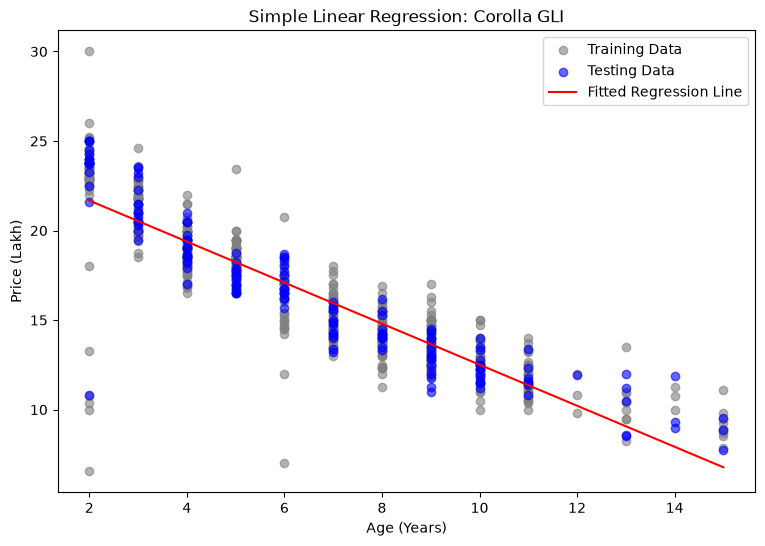

In [42]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_train["Age"],
    y_train,
    color="grey",
    alpha=0.6,
    label="Training Data"
)

plt.scatter(
    X_test["Age"],
    y_test,
    color="blue",
    alpha=0.6,
    label="Testing Data"
)

age_range = np.linspace(
    gli["Age"].min(),
    gli["Age"].max(),
    100
)

price_line = model.predict(
    pd.DataFrame({"Age": age_range})
)

plt.plot(
    age_range,
    price_line,
    color="red",
    label="Fitted Regression Line"
)

plt.title("Simple Linear Regression: Corolla GLI")
plt.xlabel("Age (Years)")
plt.ylabel("Price (Lakh)")
plt.legend()

plt.show()

### Task6(b)-Create a Residual Plot

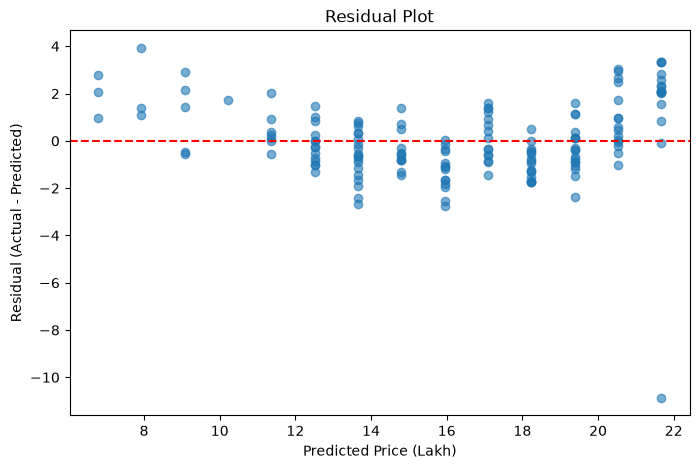

In [44]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot")
plt.xlabel("Predicted Price (Lakh)")
plt.ylabel("Residual (Actual - Predicted)")

plt.show()

### Task6(c)-Display the Five Largest Prediction Errors

In [45]:
test_results = pd.DataFrame({
    "Year": gli.loc[X_test.index, "Year"],
    "KMs Driven": gli.loc[X_test.index, "KMs Driven"],
    "Registered City": gli.loc[X_test.index, "Registered City"],
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

test_results["Absolute Error"] = abs(
    test_results["Actual Price"] -
    test_results["Predicted Price"]
)

largest_errors = test_results.sort_values(
    by="Absolute Error",
    ascending=False
).head(5)

print("T6(c): Five Largest Prediction Errors")

display(largest_errors)

T6(c): Five Largest Prediction Errors


,Year,KMs Driven,Registered City,Actual Price,Predicted Price,Absolute Error
18857,2018,NaN,Unknown,10.80,21.674990,10.874990
20280,2006,220000.0,Islamabad,11.85,7.923521,3.926479
17363,2018,NaN,Unknown,25.00,21.674990,3.325010
18980,2018,NaN,Unknown,25.00,21.674990,3.325010
16557,2018,300.0,Unknown,25.00,21.674990,3.325010


### Task6-Written Answer
The residual plot shows that most residuals are distributed around zero. There is no strong curved pattern, although some larger errors appear at higher predicted prices.

The largest errors may be related to limitations of the model and missing information in the dataset. Car prices can also depend on mileage, condition, and other factors. Since this model uses only car age, it cannot explain every price difference.

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

### Task7(a)-Predict Prices for 2018, 2015, and 2010 Corolla GLI


In [46]:
years = [2018, 2015, 2010]

ages = [2020 - year for year in years]

new_cars = pd.DataFrame({
    "Age": ages
})

predicted_prices = model.predict(new_cars)

results = pd.DataFrame({
    "Year": years,
    "Age": ages,
    "Predicted Price (Lakh)": predicted_prices
})

print("T7(a): Predicted Corolla GLI Prices")

display(results)

T7(a): Predicted Corolla GLI Prices


,Year,Age,Predicted Price (Lakh)
0,2018,2,21.674990
1,2015,5,18.237123
2,2010,10,12.507344


### Task7(b)-Predict the price of a 1995 Corolla GLI

In [47]:
car_1995 = pd.DataFrame({
    "Age": [25]
})

price_1995 = model.predict(car_1995)

print("T7(b): Predicted Price for 1995 Corolla GLI:",
      price_1995[0], "Lakh")

T7(b): Predicted Price for 1995 Corolla GLI: -4.681991173263466 Lakh


### Task7-Written Answer
The predicted price for a 1995 Corolla GLI is not believable because the model gives a negative price. A car cannot have a negative price. The model was trained on cars with ages between approximately 2 and 15 years. Therefore, predicting the price of a 25-year-old car is extrapolation outside the training data range, which can produce unreliable results.

## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.


In this lab, I loaded the cleaned Pakistan used-cars dataset and filtered the Corolla GLI cash advertisements. I used NumPy to calculate the slope and intercept and then trained a Simple Linear Regression model using Scikit-learn. I evaluated the model using the test dataset because it contains unseen data and helps measure how well the model performs on new examples. I would tell a car buyer the MAE because it explains the average prediction error in lakh. One limitation of this model is that it uses only car age and ignores other important factors such as mileage, condition, and fuel type.